# Entrenamiento y evaluación de modelos

Modelos y Simulación II, Universidad de Antioquia. Sección 4 de la guía del proyecto.

Partimos de la tabla por orden que genera `01_eda_olist.ipynb` (`data/olist_ordenes.csv.gz`, una fila por orden entregada con reseña) y comparamos seis clasificadores para predecir si la orden termina con una calificación de 1 o 2 estrellas.

El sistema se usaría en el momento en que Olist registra la entrega y antes de enviarle al cliente la encuesta de satisfacción. En ese punto ya se conocen la fecha real de entrega y el retraso frente a lo prometido, así que esas variables no filtran información de la etiqueta. El comentario de la reseña sí la filtraría y por eso no lo usamos. Un sistema que alertara en el momento de la compra no tendría las variables de entrega, que son las más informativas, y se trata de otro problema.

El código compartido con el notebook de reducción de dimensión está en la carpeta `olist/`: carga y partición de los datos (`datos.py`), preprocesamiento (`preprocesamiento.py`) y métricas con intervalos de confianza (`evaluacion.py`).

In [1]:
# En Colab: clonar el repositorio y ejecutar desde su raíz
# !git clone https://github.com/julianGuerra92/modelos-simulacion-2-olist-ml.git
# %cd modelos-simulacion-2-olist-ml
# !pip install -q imbalanced-learn umap-learn

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_validate
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImb

from olist import datos as D
from olist import evaluacion as E
from olist.preprocesamiento import preprocesador

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
C_SAT, C_INS, C_GRIS = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
FIG_DIR = "informe/figuras"
def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.pdf", bbox_inches="tight")

def eje_log(ax, valores):
    # Escala logarítmica con una marca por cada valor de la malla
    ax.set_xscale("log")
    ax.set_xticks(valores, [f"{v:g}" for v in valores])
    ax.minorticks_off()

## 1. Datos y partición

Separamos el 20 % de las órdenes como conjunto de prueba, estratificado por la etiqueta. No lo usamos hasta comparar los modelos ya ajustados. Con el 80 % restante elegimos los hiperparámetros por validación cruzada.

In [2]:
datos = D.cargar()
X_tr, X_te, y_tr, y_te = D.particion(datos)
print(f"entrenamiento: {len(y_tr):,} órdenes, {y_tr.mean():.1%} insatisfechas")
print(f"prueba:        {len(y_te):,} órdenes, {y_te.mean():.1%} insatisfechas")
print(f"variables de entrada: {X_tr.shape[1]} ({len(D.NUM)} numéricas, {len(D.BIN)} binarias, {len(D.CAT)} categóricas)")

entrenamiento: 76,659 órdenes, 12.8% insatisfechas
prueba:        19,165 órdenes, 12.8% insatisfechas
variables de entrada: 30 (23 numéricas, 3 binarias, 4 categóricas)


## 2. Configuración experimental

**Preprocesamiento.** Cada modelo es un `Pipeline` que empieza con el mismo `ColumnTransformer`, de modo que todo lo que sale de los datos lo calcula el pliegue de entrenamiento, sin mirar el de validación ni el de prueba. Eso incluye la mediana para imputar faltantes, la media y la desviación del escalado, y los niveles de cada variable categórica. Las variables con cola larga (precio, flete, peso, volumen, distancia, días hasta la transportadora) pasan por $\log(1+x)$ antes del escalado, y recortamos a cero los días negativos, que son errores de registro. Para categoría de producto, estado del cliente y estado del vendedor conservamos los 15 niveles más frecuentes en el pliegue de entrenamiento y el resto va a un nivel "Otros". Un estado que aparezca solo en prueba cae también en "Otros", así que no hay columnas nuevas en tiempo de predicción.

**Validación.** Evaluamos cada malla de hiperparámetros con validación cruzada estratificada de 5 pliegues sobre el 80 % de entrenamiento. Reportamos la media de los pliegues con un intervalo de confianza del 95 % basado en la $t$ de Student con 4 grados de libertad. En prueba el intervalo sale de 1000 remuestreos bootstrap.

**Métrica principal.** Elegimos el F1 de la clase insatisfecha. Con 12,8 % de positivos, un modelo que marque todas las órdenes como satisfechas tiene 87,2 % de exactitud, y el F1 obliga a encontrar a los insatisfechos (sensibilidad) sin llenar la alerta de falsos positivos (precisión). Como F1 depende del umbral de decisión, durante la búsqueda en malla usamos el umbral que lo maximiza en cada pliegue de validación. Para el modelo final fijamos el umbral con las predicciones fuera de pliegue del entrenamiento y lo aplicamos sin cambios a prueba. También reportamos AUC-ROC y AUC-PR, que no dependen del umbral, y la sensibilidad, la precisión y la exactitud balanceada.

**Desbalance.** Entrenamos los modelos que lo admiten con pesos inversos a la frecuencia de cada clase (`class_weight="balanced"`). En la regresión logística comparamos además contra no corregir y contra SMOTE aplicado solo dentro de los pliegues de entrenamiento. Para KNN y la red neuronal, que no aceptan pesos, el ajuste del umbral cumple esa función.

In [3]:
resultados = {}     # mejor configuración de cada modelo
mallas = {}         # resultados completos de cada búsqueda en malla

## 3. Regresión logística

Modelo paramétrico. Variamos la regularización: el inverso de su fuerza, $C$, y el tipo de penalización, L2 (`l1_ratio=0`) o L1 (`l1_ratio=1`). La L1 puede llevar coeficientes a cero, lo que funciona como una selección de variables.

In [4]:
logistica = Pipeline([
    ("pre", preprocesador()),
    ("clf", LogisticRegression(solver="liblinear", class_weight="balanced", max_iter=2000)),
])
malla_logistica = {"clf__C": [0.001, 0.01, 0.1, 1, 10], "clf__l1_ratio": [0, 1]}

gs = E.buscar(logistica, malla_logistica, X_tr, y_tr)
mallas["Regresión logística"] = gs
E.tabla_malla(gs)

,C,l1_ratio,entrenamiento,± entrenamiento,validación,± validación
0,0.001,0,0.463,0.002,0.464,0.007
1,0.010,0,0.460,0.002,0.461,0.006
2,0.010,1,0.458,0.001,0.460,0.006
3,0.100,0,0.458,0.002,0.459,0.006
4,0.100,1,0.458,0.002,0.459,0.006
5,1.000,0,0.458,0.002,0.459,0.006
6,1.000,1,0.458,0.002,0.459,0.006
7,10.000,1,0.458,0.002,0.459,0.006
8,10.000,0,0.458,0.002,0.459,0.006
9,0.001,1,0.453,0.001,0.454,0.007


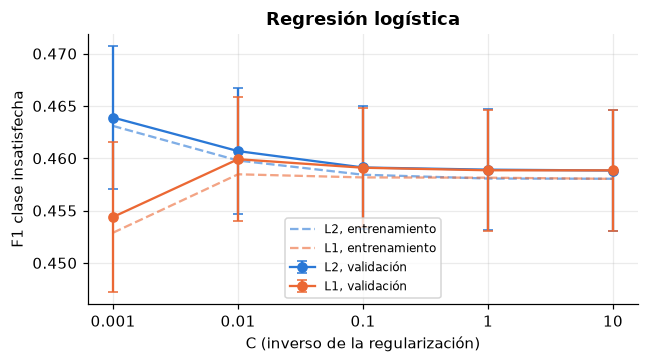

In [5]:
t = E.tabla_malla(gs)
fig, ax = plt.subplots(figsize=(6, 3.4))
for r, color, nombre in [(0, C_SAT, "L2"), (1, C_INS, "L1")]:
    s = t[t["l1_ratio"] == r].sort_values("C")
    ax.errorbar(s["C"], s["validación"], yerr=s["± validación"], color=color, marker="o", capsize=3, label=f"{nombre}, validación")
    ax.plot(s["C"], s["entrenamiento"], color=color, ls="--", alpha=0.6, label=f"{nombre}, entrenamiento")
eje_log(ax, malla_logistica["clf__C"])
ax.set_xlabel("C (inverso de la regularización)")
ax.set_ylabel("F1 clase insatisfecha")
ax.set_title("Regresión logística")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Las curvas de entrenamiento y validación casi se superponen: con 76 000 órdenes y 79 columnas el modelo lineal no sobreajusta, y lo que lo limita es el sesgo. Desde $C = 0{,}01$ el F1 de validación se queda en 0,459-0,461 con cualquiera de las dos penalizaciones. La mejor configuración es la regularización más fuerte con L2 ($C = 0{,}001$, F1 de 0,464), aunque su intervalo se traslapa con los demás. Con L1 ese mismo $C$ baja a 0,454, porque a ese nivel la penalización anula buena parte de los coeficientes.

### 3.1 Tratamiento del desbalance

Con el mejor $C$ comparamos tres opciones: sin corrección, pesos por clase y SMOTE. SMOTE va dentro de un `Pipeline` de `imblearn`, que lo aplica solo al pliegue de entrenamiento y deja el de validación con su proporción original.

In [6]:
mejor = {k.split("__")[1]: v for k, v in gs.best_params_.items()}
variantes = {
    "sin corrección": Pipeline([("pre", preprocesador()),
                                ("clf", LogisticRegression(solver="liblinear", max_iter=2000, **mejor))]),
    "pesos por clase": Pipeline([("pre", preprocesador()),
                                 ("clf", LogisticRegression(solver="liblinear", max_iter=2000, class_weight="balanced", **mejor))]),
    "SMOTE": PipelineImb([("pre", preprocesador()), ("smote", SMOTE(random_state=D.SEMILLA)),
                          ("clf", LogisticRegression(solver="liblinear", max_iter=2000, **mejor))]),
}
filas = {}
for nombre, modelo in variantes.items():
    cv = cross_validate(modelo, X_tr, y_tr, cv=E.pliegues(), scoring=E.PUNTAJES, n_jobs=-1)
    filas[nombre] = {E.METRICAS[k]: E.formato_ic(cv[f"test_{k}"].mean(), E.semiancho_ic(cv[f"test_{k}"])) for k in E.METRICAS}
pd.DataFrame(filas).T

,F1,AUC-ROC,AUC-PR,Sensibilidad,Precisión,Exactitud bal.
sin corrección,0.457 ± 0.006,0.733 ± 0.004,0.420 ± 0.011,0.407 ± 0.014,0.523 ± 0.023,0.676 ± 0.004
pesos por clase,0.464 ± 0.007,0.747 ± 0.005,0.421 ± 0.012,0.422 ± 0.007,0.515 ± 0.019,0.682 ± 0.003
SMOTE,0.463 ± 0.008,0.745 ± 0.004,0.423 ± 0.012,0.417 ± 0.019,0.523 ± 0.031,0.680 ± 0.006


Como el umbral se ajusta para maximizar F1 en las tres opciones, las diferencias en F1 son pequeñas: 0,457 sin corrección frente a 0,464 con pesos y 0,463 con SMOTE, con intervalos que se traslapan. Donde sí se nota la corrección es en el AUC-ROC, que pasa de 0,733 a 0,747 con pesos y a 0,745 con SMOTE, sin traslape con el modelo sin corregir. Pesos y SMOTE dan lo mismo, así que usamos pesos por clase en el resto de modelos: cada ajuste es más rápido, porque SMOTE agrega unas 45 000 filas sintéticas por pliegue.

In [7]:
resultados["Regresión logística"] = E.resumen_modelo(gs, X_tr, y_tr, X_te, y_te)
resultados["Regresión logística"]["parametros"]

{'C': 0.001, 'l1_ratio': 0}

## 4. K vecinos más cercanos (KNN)

Modelo no paramétrico. Variamos el número de vecinos $k$ y la ponderación: todos los vecinos pesan igual (`uniform`) o pesan según el inverso de la distancia (`distance`). La distancia es euclidiana sobre las variables ya escaladas.

In [8]:
knn = Pipeline([("pre", preprocesador()), ("clf", KNeighborsClassifier(n_jobs=1))])
malla_knn = {"clf__n_neighbors": [5, 15, 35, 75, 151, 301], "clf__weights": ["uniform", "distance"]}

gs = E.buscar(knn, malla_knn, X_tr, y_tr)
mallas["KNN"] = gs
E.tabla_malla(gs)

,n_neighbors,weights,entrenamiento,± entrenamiento,validación,± validación
0,151,distance,1.000,0.000,0.458,0.007
1,301,distance,1.000,0.000,0.457,0.004
2,75,distance,1.000,0.000,0.456,0.009
3,151,uniform,0.459,0.003,0.456,0.007
4,301,uniform,0.456,0.002,0.455,0.004
5,75,uniform,0.467,0.002,0.454,0.009
6,35,distance,1.000,0.000,0.449,0.008
7,35,uniform,0.476,0.002,0.446,0.007
8,15,distance,1.000,0.000,0.431,0.009
9,15,uniform,0.503,0.003,0.429,0.008


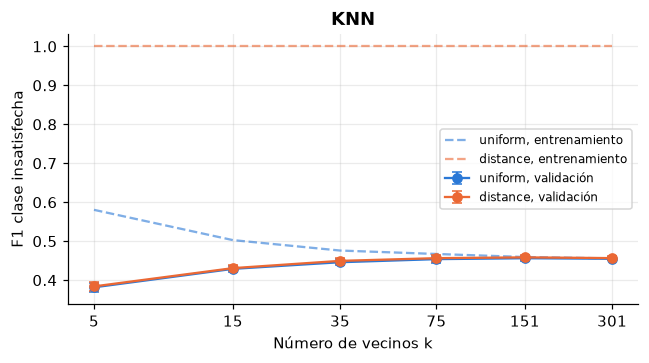

In [9]:
t = E.tabla_malla(gs)
fig, ax = plt.subplots(figsize=(6, 3.4))
for w, color in [("uniform", C_SAT), ("distance", C_INS)]:
    s = t[t["weights"] == w].sort_values("n_neighbors")
    ax.errorbar(s["n_neighbors"], s["validación"], yerr=s["± validación"], color=color, marker="o", capsize=3, label=f"{w}, validación")
    ax.plot(s["n_neighbors"], s["entrenamiento"], color=color, ls="--", alpha=0.6, label=f"{w}, entrenamiento")
eje_log(ax, malla_knn["clf__n_neighbors"])
ax.set_xlabel("Número de vecinos k")
ax.set_ylabel("F1 clase insatisfecha")
ax.set_title("KNN")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Con pocos vecinos el modelo memoriza. Con ponderación por distancia el F1 de entrenamiento es 1, porque cada orden es su propio vecino más cercano, y el de validación es el más bajo de la malla (0,38 con  = 5$). Al subir $ la validación mejora y se aplana desde 75 vecinos: 151 y 301 dan prácticamente lo mismo (0,458 y 0,457), así que el óptimo no queda fuera de la malla. KNN termina un poco por debajo de la regresión logística, aunque dentro de su intervalo. Con 79 columnas, la mayoría poco informativas (sección 6.4 del EDA), la distancia euclidiana pesa igual el retraso de la entrega que la hora de compra, y la señal útil se diluye.

In [10]:
resultados["KNN"] = E.resumen_modelo(gs, X_tr, y_tr, X_te, y_te)
resultados["KNN"]["parametros"]

{'n_neighbors': 151, 'weights': 'distance'}

## 5. Máquina de vectores de soporte

Usamos kernel gaussiano (RBF) con pesos por clase. Variamos $C$, que controla cuánto se penalizan los errores de margen, y $\gamma$, que controla el ancho del kernel. El costo de entrenar una SVM crece entre cuadrática y cúbicamente con el número de muestras, así que hicimos la búsqueda en malla y el ajuste final sobre una submuestra estratificada de 16 000 órdenes del conjunto de entrenamiento. La evaluación en prueba sí usa las 19 165 órdenes completas.

La SVM no produce probabilidades; calculamos las métricas con su función de decisión (la distancia con signo al hiperplano), que también ordena las órdenes por riesgo.

In [11]:
N_SVM = 16_000
i_svm, _ = train_test_split(np.arange(len(y_tr)), train_size=N_SVM, stratify=y_tr, random_state=D.SEMILLA)
X_svm, y_svm = X_tr.iloc[i_svm], y_tr[i_svm]

svm = Pipeline([("pre", preprocesador()), ("clf", SVC(kernel="rbf", class_weight="balanced"))])
malla_svm = {"clf__C": [0.1, 1, 10], "clf__gamma": [0.003, 0.01, 0.03]}

gs = E.buscar(svm, malla_svm, X_svm, y_svm)
mallas["SVM"] = gs
E.tabla_malla(gs)

,C,gamma,entrenamiento,± entrenamiento,validación,± validación
0,0.100,0.010,0.471,0.007,0.467,0.029
1,0.100,0.003,0.462,0.007,0.464,0.026
2,1.000,0.003,0.469,0.009,0.463,0.031
3,1.000,0.010,0.505,0.009,0.461,0.027
4,0.100,0.030,0.486,0.010,0.460,0.027
5,10.000,0.003,0.500,0.011,0.458,0.026
6,1.000,0.030,0.614,0.005,0.456,0.022
7,10.000,0.010,0.612,0.006,0.447,0.016
8,10.000,0.030,0.887,0.002,0.372,0.024


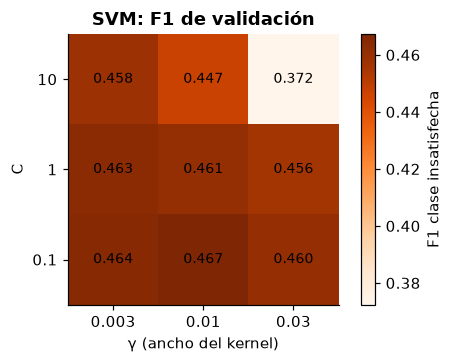

In [12]:
t = E.tabla_malla(gs).pivot(index="C", columns="gamma", values="validación").sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(4.8, 3.4))
im = ax.imshow(t.values, cmap="Oranges")
ax.set_xticks(range(t.shape[1]), [f"{g:g}" for g in t.columns])
ax.set_yticks(range(t.shape[0]), [f"{c:g}" for c in t.index])
for (a, b), v in np.ndenumerate(t.values):
    ax.text(b, a, f"{v:.3f}", ha="center", va="center", fontsize=9)
ax.set_xlabel("γ (ancho del kernel)"); ax.set_ylabel("C")
ax.set_title("SVM: F1 de validación"); ax.grid(False)
fig.colorbar(im, ax=ax, label="F1 clase insatisfecha")
plt.tight_layout(); plt.show()

El mejor resultado aparece con la penalización más baja de la malla ($C = 0{,}1$) y $\gamma = 0{,}01$, cerca del valor por defecto de scikit-learn ($1/(d \cdot \text{Var}(X)) \approx 0{,}013$). Al subir $C$ o $\gamma$ la frontera se ajusta a órdenes individuales: con $C = 10$ y $\gamma = 0{,}03$ el F1 de entrenamiento llega a 0,887 y el de validación cae a 0,372. Los intervalos de validación de la SVM son unas cuatro veces más anchos que los de los otros modelos porque cada pliegue tiene solo 3 200 órdenes.

In [13]:
resultados["SVM"] = E.resumen_modelo(gs, X_svm, y_svm, X_te, y_te)
resultados["SVM"]["parametros"]

{'C': 0.1, 'gamma': 0.01}

## 6. Resultados parciales

F1 de la clase insatisfecha para la mejor configuración de cada modelo. Entrenamiento y validación son medias de los 5 pliegues (validación con IC del 95 %); prueba usa el umbral fijado con predicciones fuera de pliegue y su IC sale de bootstrap.

In [14]:
E.tabla_resultados(resultados)

,entrenamiento,validación,prueba
modelo,,,
Regresión logística,0.463,0.464 ± 0.007,"0.457 [0.439, 0.474]"
KNN,1.000,0.458 ± 0.007,"0.457 [0.439, 0.474]"
SVM,0.471,0.467 ± 0.029,"0.460 [0.443, 0.478]"
